# Pipelines a prueba de fallas: aumento de datos, archivos rotos y monitoreo

Los tres notebooks anteriores armaron el camino de las fotos de Oxford Flowers hasta el modelo: un `Dataset` propio que lee los archivos y el `.mat` de etiquetas (`00-acceso/01_un_dataset_propio`), las transformaciones que dejan cada foto como un tensor normalizado de `[3, 224, 224]` (`01-calidad/01_transforms_para_fotos`), y la división en entrenamiento, validación y prueba con sus `DataLoader` (`02-carga/01_division_y_dataloader`). Ese camino funciona con datos limpios. Este notebook lo prepara para datos reales, que es el tema del video *Bugproof Pipelines* del curso:

- **Aumento de datos al vuelo**: transformaciones aleatorias que muestran una versión distinta de cada foto en cada época, y cómo revisar con los ojos que hagan lo que creemos.
- **Archivos rotos**: armamos una carpeta con diez problemas típicos (una descarga cortada, un archivo vacío, una foto en escala de grises, otra con transparencia, un archivo que falta…) y vemos qué le pasa a cada uno.
- **Qué detecta `Image.verify()`** y qué no.
- **Un `__getitem__` robusto** que registra los errores y sigue, y lo que esa estrategia esconde.
- **Revisar antes de entrenar**, con un límite de errores que detiene todo si se supera.
- **Monitoreo**: contar qué fotos se cargan, cuántas veces y cuánto tarda cada una.

El notebook tarda alrededor de un minuto en una CPU. Crea la carpeta `modulo-3/data/flores_corruptas`, con 200 fotos copiadas y algunas dañadas a propósito, y la vuelve a armar en cada ejecución.

**Contenido**

1. Preparación
2. Las flores, en corto
3. Aumento de datos al vuelo
4. Ver el aumento antes de entrenar
5. Un dataset con archivos rotos
6. El pipeline ingenuo
7. `verify()` y `load()`: qué detecta cada uno
8. Un `__getitem__` robusto
9. Lo que esconde saltar a la siguiente
10. Revisar una vez, antes de entrenar
11. Monitorear la carga
12. Con varios procesos
13. Resumen y ejercicios

## 1. Preparación

Las librerías de los notebooks anteriores, más `PIL.ImageFile` para un ajuste de Pillow que aparece en la sección 7 y `pickle` para la sección 12.

In [1]:
import collections
import csv
import io
import math
import os
import pickle
import shutil
import sys
import time

import numpy as np
import scipy.io
import torch
from PIL import Image, ImageFile
from torch.utils.data import DataLoader, Dataset, RandomSampler, default_collate
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"                       # modulo-3/data
FLORES = f"{RAIZ}/flowers-102"

Versión de PyTorch: 2.11.0+cpu


## 2. Las flores, en corto

Repetimos en pocas líneas lo que armaron los notebooks anteriores: las rutas de las 8.189 fotos, las etiquetas del `.mat` corridas de 1–102 a 0–101 (`00-acceso/01_un_dataset_propio`), un `Dataset` que abre cada foto recién cuando se la piden, y la transformación determinista de validación (`01-calidad/01_transforms_para_fotos`). En esta versión corta dejamos fuera el `with` y el `convert("RGB")` que usan esos notebooks: las 8.189 fotos de Oxford son RGB, y la sección 6 muestra qué pasa sin esas defensas cuando los archivos no lo son. Para normalizar usamos la media y la desviación de ImageNet, como en el curso; `01-calidad/01_transforms_para_fotos` las compara con las de las flores. Los nombres de las clases los tomamos de `datasets.Flowers102`, que además descarga los archivos la primera vez.

In [2]:
datasets.Flowers102(root=RAIZ, download=True)          # solo para descargar los archivos la primera vez
NOMBRES = datasets.Flowers102.classes                  # los nombres en inglés de las 102 clases

etiquetas_todas = scipy.io.loadmat(f"{FLORES}/imagelabels.mat")["labels"][0] - 1     # 1..102 -> 0..101
rutas_todas = [f"{FLORES}/jpg/image_{i + 1:05d}.jpg" for i in range(len(etiquetas_todas))]


class Flores(Dataset):
    """Rutas y etiquetas en memoria; cada foto se abre recién cuando se pide."""

    def __init__(self, rutas, etiquetas, transformacion=None):
        self.rutas = list(rutas)
        self.etiquetas = [int(e) for e in etiquetas]
        self.transformacion = transformacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        imagen = Image.open(self.rutas[i])
        if self.transformacion:
            imagen = self.transformacion(imagen)
        return imagen, self.etiquetas[i]


MEDIA = [0.485, 0.456, 0.406]          # media y desviación de ImageNet, por canal
DESVIACION = [0.229, 0.224, 0.225]

transformacion_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIACION),
])

flores_val = Flores(rutas_todas, etiquetas_todas, transformacion_val)
x, y = flores_val[7999]
print(len(flores_val), "fotos   una muestra:", tuple(x.shape), "  etiqueta:", y, f"({NOMBRES[y]})")

8189 fotos   una muestra: (3, 224, 224)   etiqueta: 101 (blackberry lily)


La foto 7999 es una *blackberry lily*, un lirio anaranjado con manchas. No es simétrica, así que se va a notar cuando el aumento la voltee. La usamos de ejemplo en las dos secciones siguientes.

## 3. Aumento de datos al vuelo

El **aumento de datos** (*data augmentation*) aplica transformaciones aleatorias cada vez que se carga una foto. En cada época el modelo ve una versión algo distinta de cada flor, sin ocupar más disco: las versiones no se guardan, se fabrican al pedirlas. Así le cuesta más memorizar lo particular de cada foto (el encuadre, el ángulo, la luz) y tiene que fijarse en lo que se repite entre fotos de la misma clase: la forma y el color de la flor. Usamos cuatro transformaciones de `torchvision`:

- `RandomResizedCrop(224, scale=(0.5, 1.0))` recorta un trozo de la foto con un área y una proporción al azar, y lo lleva a 224 × 224. `scale` es el rango del área del recorte, como fracción del área de la foto ([`RandomResizedCrop`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomResizedCrop.html)).
- `RandomHorizontalFlip()` voltea la foto como en un espejo, con probabilidad 0.5 por defecto ([`RandomHorizontalFlip`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomHorizontalFlip.html)).
- `RandomRotation(15)` la gira en un ángulo al azar entre −15° y 15° ([`RandomRotation`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomRotation.html)).
- `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)` multiplica el brillo, el contraste y la saturación por factores al azar entre 0.8 y 1.2 ([`ColorJitter`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.ColorJitter.html)).

Van antes de `ToTensor` y `Normalize`, que quedan igual que en validación.

El aumento va **solo en el entrenamiento**. La validación y la prueba miden cómo le va al modelo, y una medición tiene que dar lo mismo cada vez que se repite. Lo comprobamos pidiendo dos veces la misma foto a cada dataset:

In [3]:
transformacion_ent = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIACION),
])

flores_ent = Flores(rutas_todas, etiquetas_todas, transformacion_ent)

FLOR = 7999
a, _ = flores_val[FLOR]
b, _ = flores_val[FLOR]
c, _ = flores_ent[FLOR]
d, _ = flores_ent[FLOR]
print("validación, dos veces la misma foto   -> ¿iguales?", torch.equal(a, b))
print("entrenamiento, dos veces la misma foto -> ¿iguales?", torch.equal(c, d),
      f"  (diferencia media por píxel: {(c - d).abs().mean():.3f})")

validación, dos veces la misma foto   -> ¿iguales? True
entrenamiento, dos veces la misma foto -> ¿iguales? False   (diferencia media por píxel: 0.879)


La validación entrega exactamente el mismo tensor. El entrenamiento entrega otro: los píxeles difieren en 0.88 en promedio, en una escala normalizada donde la desviación típica de un píxel es más o menos 1. Es lo que dice la documentación de `torchvision`: las transformaciones aleatorias "randomly sample some parameter each time they're called" ([*Transforming images, videos, boxes and more*](https://docs.pytorch.org/vision/0.26/transforms.html#transform-classes-functionals-and-kernels)).

¿De dónde sale el azar? Del generador de números aleatorios de PyTorch. Si fijamos la semilla justo antes de pedir la foto, sale la misma versión:

In [4]:
torch.manual_seed(123)
e, _ = flores_ent[FLOR]
torch.manual_seed(123)
f, _ = flores_ent[FLOR]
print("misma semilla antes de pedirla -> ¿iguales?", torch.equal(e, f))

misma semilla antes de pedirla -> ¿iguales? True


Así se reproduce un resultado, como hacemos en todos estos notebooks con `torch.manual_seed(0)`. Con `num_workers > 0` hay un detalle más: cada proceso de carga recibe su propia semilla, "base_seed + worker_id" según la documentación de `DataLoader` ([*Randomness in multi-process data loading*](https://docs.pytorch.org/docs/2.11/data.html#randomness-in-multi-process-data-loading)).

**¿Qué tan grande es el recorte?** `RandomResizedCrop` viene del entrenamiento de las redes Inception (la documentación dice "This is popularly used to train the Inception networks"), y su rango por defecto es `scale=(0.08, 1.0)`: permite recortes de apenas el 8% de la foto. Nosotros usamos `(0.5, 1.0)`. Para comparar los dos rangos, sorteamos 2.000 recortes de nuestra foto con cada uno. `get_params` es el método que sortea el recorte sin aplicarlo, y entrega su posición y su tamaño:

In [5]:
foto = Image.open(rutas_todas[FLOR])
ancho, alto = foto.size
print("tamaño original:", ancho, "x", alto)

for escala in [(0.08, 1.0), (0.5, 1.0)]:
    areas = []
    for _ in range(2000):
        _, _, h, w = transforms.RandomResizedCrop.get_params(foto, scale=escala, ratio=(3 / 4, 4 / 3))
        areas.append(h * w / (alto * ancho))
    areas = torch.tensor(areas)
    print(f"scale={escala}:  área del recorte, mediana {areas.median():.0%}   "
          f"menos de un cuarto de la foto: {(areas < 0.25).float().mean():.0%} de las veces")

tamaño original: 679 x 500


scale=(0.08, 1.0):  área del recorte, mediana 41%   menos de un cuarto de la foto: 27% de las veces


scale=(0.5, 1.0):  área del recorte, mediana 63%   menos de un cuarto de la foto: 0% de las veces


Con el rango por defecto, la mitad de los recortes se queda con menos del 41% de la foto, y uno de cada cuatro (27%) con menos de un cuarto. En una foto con la flor al centro, un recorte así puede quedarse solo con hojas, y la etiqueta seguiría diciendo "lirio". Con `scale=(0.5, 1.0)` ningún recorte baja de la mitad de la foto.

Ningún rango es el correcto para todo: depende de cuánto de la foto ocupa lo que importa. Por eso hay que mirar el resultado, que es lo que hace la sección siguiente.

## 4. Ver el aumento antes de entrenar

Un aumento de datos con un error no avisa: el entrenamiento corre igual. La revisión más directa, la que propone el video *Bugproof Pipelines*, es mirar varias versiones aumentadas de la misma foto. Antes de graficar hay que **deshacer la normalización**: `Normalize` dejó valores alrededor de 0, negativos incluidos, y `imshow` espera colores entre 0 y 1. Desnormalizar es la operación inversa: multiplicar por la desviación y sumar la media.

Aun desnormalizada, una imagen puede tener valores fuera de [0, 1] si algo salió mal en el camino. `imshow` los recortaría por su cuenta, pero escribiendo una advertencia. Preferimos recortarlos nosotros con `clamp(0, 1)` y contar cuántos píxeles había fuera, porque ese número es en sí mismo un diagnóstico. La función también mide cuánto difieren las versiones de la primera.

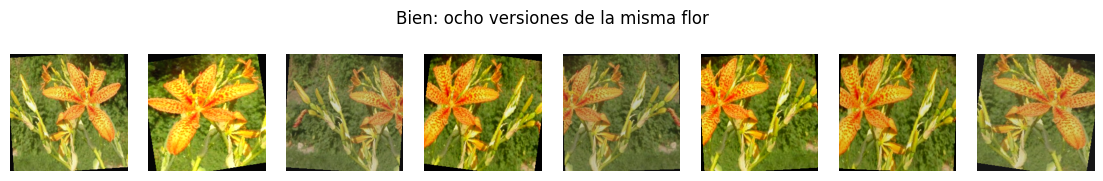

diferencia media con la primera versión: 0.735   píxeles fuera de [0, 1] al desnormalizar: 0.0%


In [6]:
media_t = torch.tensor(MEDIA).view(3, 1, 1)
desviacion_t = torch.tensor(DESVIACION).view(3, 1, 1)


def desnormalizar(x):
    """Deshace Normalize: de vuelta a la escala [0, 1] de ToTensor."""
    return x * desviacion_t + media_t


def mostrar_versiones(dataset, i, titulo, n=8):
    versiones = torch.stack([dataset[i][0] for _ in range(n)])
    imagenes = desnormalizar(versiones)
    fuera = ((imagenes < 0) | (imagenes > 1)).float().mean().item()
    distintas = (versiones - versiones[0]).abs().mean().item()
    fig, ejes = plt.subplots(1, n, figsize=(1.4 * n, 1.8))
    for eje, imagen in zip(ejes, imagenes):
        eje.imshow(imagen.clamp(0, 1).permute(1, 2, 0))       # [3, H, W] -> [H, W, 3] para imshow
        eje.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    print(f"diferencia media con la primera versión: {distintas:.3f}   "
          f"píxeles fuera de [0, 1] al desnormalizar: {fuera:.1%}")


torch.manual_seed(0)
mostrar_versiones(flores_ent, FLOR, "Bien: ocho versiones de la misma flor")

Las ocho se reconocen como la misma flor: cambian el encuadre, el lado hacia donde mira, la inclinación y un poco la luz. Ningún píxel quedó fuera de [0, 1].

Las esquinas negras de algunas versiones vienen de `RandomRotation`: al girar, las esquinas quedan fuera de la foto original y se rellenan con `fill`, que vale 0 (negro) por defecto. El modelo también ve esas esquinas. Con giros de 15° son triángulos chicos; con giros grandes ocuparían buena parte de la imagen.

El video describe cuatro resultados posibles de esta revisión:

| Lo que se ve | Diagnóstico |
|---|---|
| La flor se reconoce en todas, con variaciones | el aumento funciona |
| Todas iguales | el aumento no se está aplicando |
| Parecen arte abstracto | el aumento es demasiado agresivo |
| Negras, saturadas o con colores raros | un problema de normalización |

Acabamos de ver el primero. Provocamos los otros tres a propósito, para saber reconocerlos.

**Todas iguales.** Una forma común de llegar aquí es querer ahorrarse el costo de transformar en cada época (`00-datos/01_transforms_dataset_y_dataloader` del módulo 2, sección 9) aplicando las transformaciones una vez, al construir el dataset. Con transformaciones deterministas eso funciona. Con aleatorias, congela una sola versión de cada foto:

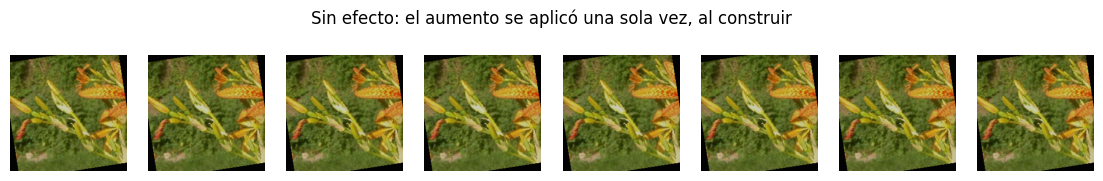

diferencia media con la primera versión: 0.000   píxeles fuera de [0, 1] al desnormalizar: 0.0%


In [7]:
class FloresPrecargadas(Dataset):
    """Un intento de acelerar: transformar todo una vez, en __init__."""

    def __init__(self, rutas, etiquetas, transformacion):
        self.imagenes = [transformacion(Image.open(r)) for r in rutas]
        self.etiquetas = [int(e) for e in etiquetas]

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, i):
        return self.imagenes[i], self.etiquetas[i]


precargadas = FloresPrecargadas(rutas_todas[FLOR:FLOR + 1], etiquetas_todas[FLOR:FLOR + 1], transformacion_ent)
mostrar_versiones(precargadas, 0, "Sin efecto: el aumento se aplicó una sola vez, al construir")

Ocho copias idénticas: la diferencia con la primera es exactamente 0. El modelo vería siempre el mismo recorte, y el aumento no aumentaría nada. Peor aún, el recorte que quedó congelado deja la flor contra un borde: en cada época el modelo vería la misma versión mala. Hay otra forma de llegar al mismo síntoma: los subconjuntos de `random_split` comparten el dataset de origen, así que la transformación que se le pone a uno queda puesta en todos (`02-carga/01_division_y_dataloader`). Si la última que se asignó fue la de validación, el entrenamiento se queda sin aumento.

**Demasiado agresivo.** Recortes de entre el 2% y el 10% de la foto, giros de hasta 180°, volteos verticales y cambios fuertes de brillo, contraste, saturación y tono:

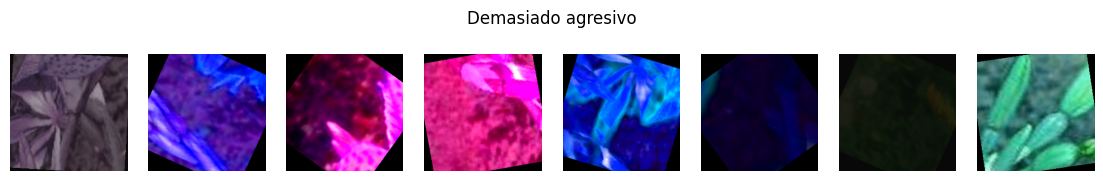

diferencia media con la primera versión: 1.005   píxeles fuera de [0, 1] al desnormalizar: 0.0%


In [8]:
transformacion_agresiva = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.02, 0.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIACION),
])
torch.manual_seed(0)
mostrar_versiones(Flores(rutas_todas, etiquetas_todas, transformacion_agresiva), FLOR,
                  "Demasiado agresivo")

Ninguna se reconoce como un lirio: son manchas de colores, dos casi negras, con esquinas negras grandes por los giros. La diferencia media con la primera versión (1.005) es más alta que con el aumento razonable (0.735), pero ese número solo no basta para decidir. Lo que decide es si una persona todavía reconocería la flor: si no puede, es difícil que el modelo aprenda algo útil de esa imagen, y la etiqueta "lirio" pasa a ser ruido.

**Normalización equivocada.** El último caso: `Normalize` quedó dos veces en la lista, por ejemplo al juntar dos `Compose` que ya lo traían. Desnormalizamos una vez, como siempre:

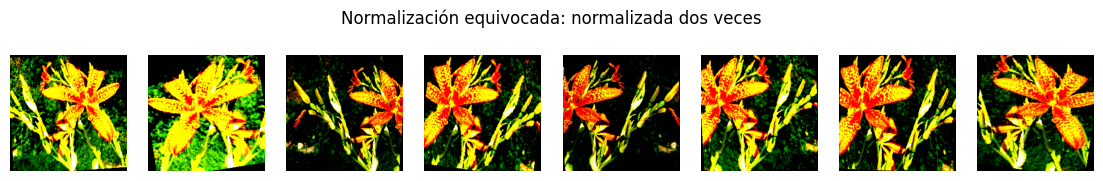

diferencia media con la primera versión: 3.247   píxeles fuera de [0, 1] al desnormalizar: 77.4%


In [9]:
transformacion_doble = transforms.Compose([
    *transformacion_ent.transforms,
    transforms.Normalize(MEDIA, DESVIACION),           # Normalize por segunda vez
])
torch.manual_seed(0)
flores_doble = Flores(rutas_todas, etiquetas_todas, transformacion_doble)
mostrar_versiones(flores_doble, FLOR, "Normalización equivocada: normalizada dos veces")

Colores saturados y fondo negro: el 77.4% de los píxeles quedó fuera de [0, 1] y hubo que recortarlo. La forma de la flor se reconoce, pero los colores no son los de la foto.

Este error también se ve sin mirar imágenes, en la media y la desviación de cada canal de un lote. Con 32 fotos al azar:

In [10]:
def estadisticas(dataset, indices):
    lote = torch.stack([dataset[i][0] for i in indices])
    return lote.mean(dim=(0, 2, 3)), lote.std(dim=(0, 2, 3))


indices = torch.randperm(len(rutas_todas), generator=torch.Generator().manual_seed(1))[:32].tolist()
for nombre, dataset in [("validación, sin aumento", flores_val),
                        ("aumento, normalizada una vez", flores_ent),
                        ("aumento, normalizada dos veces", flores_doble)]:
    m, s = estadisticas(dataset, indices)
    print(f"{nombre:31s} media por canal {[round(v, 2) for v in m.tolist()]}   desviación {[round(v, 2) for v in s.tolist()]}")

validación, sin aumento         media por canal [0.11, -0.31, -0.4]   desviación [1.3, 1.08, 1.27]


aumento, normalizada una vez    media por canal [-0.18, -0.48, -0.61]   desviación [1.34, 1.12, 1.2]


aumento, normalizada dos veces  media por canal [-3.09, -4.39, -4.59]   desviación [5.68, 4.77, 5.16]


Sin aumento, la media de cada canal queda entre −0.40 y 0.11 y la desviación entre 1.08 y 1.30: cerca de 0 y de 1, aunque no exactamente, por dos razones. La media y la desviación que usamos para normalizar son las de ImageNet, no las de estas flores, y 32 fotos son una muestra chica. Con el aumento, las medias bajan entre 0.17 y 0.29 (quedan entre −0.61 y −0.18) y la desviación casi no cambia (entre 1.12 y 1.34): los recortes al azar cambian qué parte de cada foto entra, y los giros agregan esquinas negras. Ninguna de estas diferencias es un error. Normalizadas dos veces, la media baja a entre −3.09 y −4.59 y la desviación sube a entre 4.77 y 5.68. Una red puede entrenar con eso, pero partiría con entradas en una escala muy distinta de la que suponen la inicialización de sus pesos y las tasas de aprendizaje habituales. Imprimir la media y la desviación de un lote es un chequeo de una línea que conviene hacer antes de cada entrenamiento.

## 5. Un dataset con archivos rotos

Oxford Flowers viene limpio: las 8.189 fotos se abren sin problemas. Los datos reales no siempre llegan así, y el laboratorio del curso trabaja con una versión dañada de las flores. Armamos la nuestra: copiamos dos fotos al azar de cada una de 100 clases, 200 en total, con nombres nuevos (`flor_000.jpg` a `flor_199.jpg`) y una lista `etiquetas.csv` con el archivo y la etiqueta de cada una. Después estropeamos diez a propósito:

| Problema | Qué le hacemos | Cómo pasa en la práctica |
|---|---|---|
| truncada | se conserva el 60% de los bytes | una descarga o una copia que se cortó |
| vacía | 0 bytes | un error al guardar, un disco lleno |
| texto | un texto con extensión `.jpg` | alguien guardó otra cosa con ese nombre |
| gris | escala de grises: un canal | fotos de otra fuente |
| diminuta | 24 × 18 píxeles | una miniatura en lugar de la foto |
| con alfa | PNG con canal de transparencia (RGBA), aunque sin zonas transparentes | capturas o imágenes editadas |
| cmyk | JPEG en CMYK: cuatro canales | imágenes preparadas para imprenta |
| faltante | está en la lista pero no en el disco | un archivo borrado o movido |
| gigante | sana, pero 8 veces más grande por lado | una foto de cámara sin achicar |
| png disfrazado | un PNG con extensión `.jpg` | renombrar un archivo no cambia su formato |

Las dos últimas no son errores: la gigante solo es lenta, y el PNG disfrazado sirve para ver si la extensión importa.

In [11]:
CORRUPTAS = f"{RAIZ}/flores_corruptas"
if os.path.exists(CORRUPTAS):
    shutil.rmtree(CORRUPTAS)          # se arma de nuevo en cada ejecución
os.makedirs(CORRUPTAS)

generador = torch.Generator().manual_seed(0)
elegidas = []
for clase in range(100):                                  # dos fotos al azar de cada una de 100 clases
    de_la_clase = [i for i, e in enumerate(etiquetas_todas) if e == clase]
    elegidas += [de_la_clase[j] for j in torch.randperm(len(de_la_clase), generator=generador)[:2].tolist()]
elegidas = [elegidas[j] for j in torch.randperm(len(elegidas), generator=generador).tolist()]   # en desorden

archivos, etiquetas_c = [], []
for k, i in enumerate(elegidas):
    nombre = f"flor_{k:03d}.jpg"
    shutil.copy(rutas_todas[i], f"{CORRUPTAS}/{nombre}")
    archivos.append(nombre)
    etiquetas_c.append(int(etiquetas_todas[i]))

DANOS = {12: "truncada", 37: "vacía", 58: "texto", 81: "gris", 104: "diminuta",
         127: "con alfa", 143: "cmyk", 166: "faltante", 181: "gigante", 195: "png disfrazado"}

for k, dano in DANOS.items():
    ruta = f"{CORRUPTAS}/{archivos[k]}"
    if dano == "truncada":
        contenido = open(ruta, "rb").read()
        open(ruta, "wb").write(contenido[: len(contenido) * 6 // 10])
    elif dano == "vacía":
        open(ruta, "wb").close()
    elif dano == "texto":
        open(ruta, "w").write("archivo,etiqueta\nflor_000.jpg,76\n")
    elif dano == "gris":
        Image.open(ruta).convert("L").save(ruta)
    elif dano == "diminuta":
        Image.open(ruta).resize((24, 18)).save(ruta)
    elif dano == "con alfa":
        Image.open(ruta).convert("RGBA").save(ruta.replace(".jpg", ".png"))
        os.remove(ruta)
        archivos[k] = archivos[k].replace(".jpg", ".png")
    elif dano == "cmyk":
        Image.open(ruta).convert("CMYK").save(ruta)
    elif dano == "faltante":
        os.remove(ruta)
    elif dano == "gigante":
        imagen = Image.open(ruta)
        imagen.resize((imagen.width * 8, imagen.height * 8)).save(ruta, quality=95)
    elif dano == "png disfrazado":
        Image.open(ruta).save(ruta, format="PNG")

with open(f"{CORRUPTAS}/etiquetas.csv", "w", newline="") as archivo_csv:
    escritor = csv.writer(archivo_csv)
    escritor.writerow(["archivo", "etiqueta"])
    escritor.writerows(zip(archivos, etiquetas_c))

en_disco = sorted(os.listdir(CORRUPTAS))
print("filas en etiquetas.csv:", len(archivos), "   archivos en la carpeta:", len(en_disco))
for k, dano in DANOS.items():
    ruta = f"{CORRUPTAS}/{archivos[k]}"
    tamano = f"{os.path.getsize(ruta) / 1000:7.1f} KB" if os.path.exists(ruta) else "   no existe"
    print(f"  {archivos[k]:14s} {dano:15s} {tamano}")

filas en etiquetas.csv: 200    archivos en la carpeta: 200
  flor_012.jpg   truncada           15.2 KB
  flor_037.jpg   vacía               0.0 KB
  flor_058.jpg   texto               0.0 KB
  flor_081.jpg   gris               20.5 KB
  flor_104.jpg   diminuta            0.9 KB
  flor_127.png   con alfa          566.4 KB
  flor_143.jpg   cmyk              185.7 KB
  flor_166.jpg   faltante           no existe
  flor_181.jpg   gigante          1712.5 KB
  flor_195.jpg   png disfrazado    375.2 KB


200 filas en la lista y 200 archivos en la carpeta, pero no son los mismos 200: `flor_166.jpg` no existe, y el archivo número 200 es el propio `etiquetas.csv`. Contar archivos no basta para saber si la lista calza con el disco.

## 6. El pipeline ingenuo

Un `Dataset` parecido al de `00-acceso/01_un_dataset_propio`: lee la lista una sola vez en `__init__` (`02-carga/01_division_y_dataloader` muestra lo que cuesta leerla en cada `__getitem__`) y abre cada foto cuando se la piden. A diferencia de aquel, no llama a `convert("RGB")` ni tiene ninguna otra defensa: se las quitamos a propósito, para ver qué hace cada archivo dañado. Le pedimos los diez archivos especiales, uno por uno:

In [12]:
class FloresCSV(Dataset):
    """Lee la lista de archivos una vez y abre cada foto cuando se pide. Sin defensas."""

    def __init__(self, carpeta, transformacion=None):
        self.carpeta = carpeta
        self.transformacion = transformacion
        with open(f"{carpeta}/etiquetas.csv", newline="") as archivo_csv:
            filas = list(csv.DictReader(archivo_csv))
        self.archivos = [fila["archivo"] for fila in filas]
        self.etiquetas = [int(fila["etiqueta"]) for fila in filas]

    def __len__(self):
        return len(self.archivos)

    def __getitem__(self, i):
        imagen = Image.open(f"{self.carpeta}/{self.archivos[i]}")
        if self.transformacion:
            imagen = self.transformacion(imagen)
        return imagen, self.etiquetas[i]


ingenuo = FloresCSV(CORRUPTAS, transformacion_val)
for k, dano in DANOS.items():
    try:
        x, y = ingenuo[k]
        print(f"{dano:15s} sin error, forma {tuple(x.shape)}")
    except Exception as error:
        print(f"{dano:15s} {type(error).__name__}: {error}")

truncada        OSError: image file is truncated (4 bytes not processed)


vacía           UnidentifiedImageError: cannot identify image file '../data/flores_corruptas/flor_037.jpg'
texto           UnidentifiedImageError: cannot identify image file '../data/flores_corruptas/flor_058.jpg'
gris            RuntimeError: output with shape [1, 224, 224] doesn't match the broadcast shape [3, 224, 224]


diminuta        sin error, forma (3, 224, 224)
con alfa        RuntimeError: The size of tensor a (4) must match the size of tensor b (3) at non-singleton dimension 0
cmyk            RuntimeError: The size of tensor a (4) must match the size of tensor b (3) at non-singleton dimension 0
faltante        FileNotFoundError: [Errno 2] No such file or directory: '../data/flores_corruptas/flor_166.jpg'


gigante         sin error, forma (3, 224, 224)
png disfrazado  sin error, forma (3, 224, 224)


Siete de los diez fallan, cada uno a su manera:

- **Al abrir.** El vacío y el de texto dan `UnidentifiedImageError` (Pillow no reconoce ningún formato de imagen en el contenido), y el faltante `FileNotFoundError`. Son dos de las excepciones que la documentación de `Image.open` dice que puede lanzar ([`PIL.Image.open`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.open)).
- **Al decodificar.** El truncado se abre sin problemas y falla después: `image file is truncated`. Es que `Image.open` es perezoso: "this function identifies the file, but the file remains open and the actual image data is not read from the file until you try to process the data". Los píxeles se leen recién cuando `Resize` los necesita, y ahí se descubre que faltan.
- **En `Normalize`.** La gris, la con alfa y la CMYK se abren y se decodifican bien, y fallan al normalizar: tienen 1, 4 y 4 canales, y la media y la desviación tienen 3. Fíjate en que los mensajes hablan de formas de tensores y no nombran ningún archivo. Al `Dataset` de `00-acceso/01_un_dataset_propio` estas tres no lo habrían botado: su `convert("RGB")` las deja con tres canales.

Los otros tres pasan sin error. La gigante, porque no tiene nada malo. El PNG disfrazado, porque Pillow reconoce el formato por el contenido y no por la extensión. Y la diminuta, que es la más traicionera, porque pasa pero no debería: la vemos en un momento.

Si el pipeline no tuviera `Normalize`, la foto gris pasaría `__getitem__` y el error aparecería más lejos, al apilar el lote en el `DataLoader`. `default_collate` es la función que hace ese apilado:

In [13]:
sin_normalize = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor()])
gris = sin_normalize(Image.open(f"{CORRUPTAS}/{archivos[81]}"))
color = sin_normalize(Image.open(f"{CORRUPTAS}/{archivos[0]}"))
print("gris:", tuple(gris.shape), "  color:", tuple(color.shape))
try:
    default_collate([(gris, 0), (color, 1)])
except RuntimeError as error:
    print("RuntimeError:", error)

gris: (1, 224, 224)   color: (3, 224, 224)
RuntimeError: stack expects each tensor to be equal size, but got [1, 224, 224] at entry 0 and [3, 224, 224] at entry 1


Ahora el mensaje dice "at entry 0": la posición dentro del lote, que no sirve para encontrar el archivo.

La diminuta no da ningún error. Mira lo que recibe el modelo:

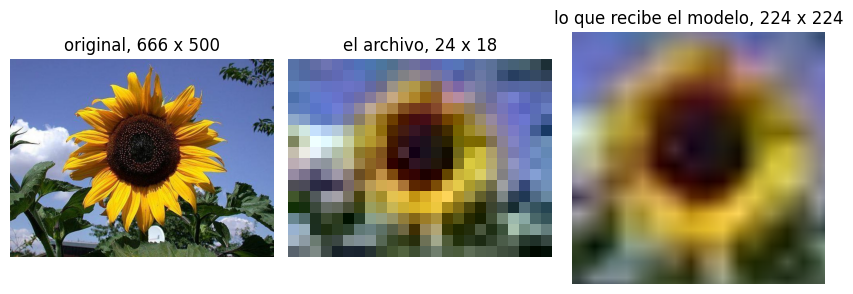

etiqueta: 53 (sunflower)


In [14]:
original = Image.open(rutas_todas[elegidas[104]])
diminuta = Image.open(f"{CORRUPTAS}/{archivos[104]}")
x, y = ingenuo[104]
fig, ejes = plt.subplots(1, 3, figsize=(8.5, 2.9))
ejes[0].imshow(original)
ejes[0].set_title(f"original, {original.width} x {original.height}")
ejes[1].imshow(diminuta)
ejes[1].set_title(f"el archivo, {diminuta.width} x {diminuta.height}")
ejes[2].imshow(desnormalizar(x).clamp(0, 1).permute(1, 2, 0))
ejes[2].set_title("lo que recibe el modelo, 224 x 224")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()
print("etiqueta:", y, f"({NOMBRES[y]})")

`Resize(256)` lleva el lado corto de 18 a 256 píxeles, unas 14 veces más grande, y el modelo recibe una mancha borrosa con la etiqueta de girasol. Ninguna excepción la va a delatar: hace falta una regla explícita, como un tamaño mínimo.

Ahora todo junto, con un `DataLoader` como en un entrenamiento, con lotes de 16 mezclados:

In [15]:
cargador = DataLoader(ingenuo, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(0))
lotes_completos, imagenes_vistas = 0, 0
try:
    for x, y in cargador:
        lotes_completos += 1
        imagenes_vistas += len(y)
except Exception as error:
    print(f"la época se cayó en el lote {lotes_completos + 1} de {len(cargador)}, "
          f"después de {imagenes_vistas} imágenes")
    print(f"{type(error).__name__}: {error}")

malos, total, por_lote = 7, 200, 16
print(f"\nprobabilidad de que un lote de {por_lote} no traiga ninguno de los {malos} archivos que rompen: "
      f"{math.comb(total - malos, por_lote) / math.comb(total, por_lote):.0%}")

la época se cayó en el lote 1 de 13, después de 0 imágenes
RuntimeError: The size of tensor a (4) must match the size of tensor b (3) at non-singleton dimension 0

probabilidad de que un lote de 16 no traiga ninguno de los 7 archivos que rompen: 55%


Se cayó en el primer lote, antes de entregar una sola imagen, con el error de los cuatro canales: el lote traía la foto con alfa o la CMYK, y el mensaje no dice cuál. Que fuera justo el primer lote tuvo algo de suerte: con 7 archivos que rompen entre 200, un lote de 16 tiene un 55% de probabilidad de salir limpio. Lo seguro es que la época se cae, en un lote o en otro, porque recorre todos los archivos.

¿Y si hubiera un solo archivo malo entre las 8.189 flores? Con `shuffle=True` cada época las recorre todas, así que la primera época siempre llega a él, en una posición al azar. Simulamos 1.000 órdenes de una época con lotes de 32, sin cargar fotos, solo mirando en qué posición queda el archivo malo:

In [16]:
n, por_lote, malo = len(rutas_todas), 32, 1234
lotes_por_epoca = math.ceil(n / por_lote)
caidas = []
for semilla in range(1000):
    orden = torch.randperm(n, generator=torch.Generator().manual_seed(semilla))
    posicion = (orden == malo).nonzero().item()
    caidas.append(posicion // por_lote + 1)
caidas = torch.tensor(caidas, dtype=torch.float)
print(f"{lotes_por_epoca} lotes por época: la primera época se cae en el lote {caidas.mean():.0f} en promedio, "
      f"en cualquiera entre el {caidas.min():.0f} y el {caidas.max():.0f}")

256 lotes por época: la primera época se cae en el lote 126 en promedio, en cualquiera entre el 1 y el 256


En promedio, a la mitad de la primera época. Si una época dura horas, se pierden horas, y al relanzar el entrenamiento sin arreglar nada se vuelve a caer. Es el escenario del video: una sola imagen corrupta bota un entrenamiento largo.

## 7. `verify()` y `load()`: qué detecta cada uno

La defensa que propone el curso empieza por `Image.verify()`. Según la documentación de Pillow, "this method attempts to determine if the file is broken, without actually decoding the image data", y "If you need to load the image after using this method, you must reopen the image file" ([`Image.verify`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.verify)). Que no decodifique la hace barata. Pero ¿qué detecta?

La función siguiente lleva cada archivo por cuatro etapas y anota la primera en que falla: abrir, `verify()`, `load()` (que decodifica los píxeles, [`Image.load`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.load)) y transformar. También anota el formato que Pillow reconoce en cada archivo:

In [17]:
def etapa_que_falla(ruta):
    try:
        imagen = Image.open(ruta)
    except Exception as error:
        return "abrir", type(error).__name__
    try:
        imagen.verify()
    except Exception as error:
        return "verify", type(error).__name__
    imagen = Image.open(ruta)                # verify deja la imagen inutilizable: hay que reabrir
    try:
        imagen.load()
    except Exception as error:
        return "load", type(error).__name__
    try:
        transformacion_val(imagen)
    except Exception as error:
        return "transformar", type(error).__name__
    return "ninguna", ""


print(f"{'archivo':15s} {'formato real':13s} {'falla en':12s} error")
for k, dano in DANOS.items():
    ruta = f"{CORRUPTAS}/{archivos[k]}"
    try:
        formato = Image.open(ruta).format
    except Exception:
        formato = "-"
    etapa, error = etapa_que_falla(ruta)
    print(f"{dano:15s} {formato:13s} {etapa:12s} {error}")

archivo         formato real  falla en     error
truncada        JPEG          load         OSError
vacía           -             abrir        UnidentifiedImageError
texto           -             abrir        UnidentifiedImageError
gris            JPEG          transformar  RuntimeError
diminuta        JPEG          ninguna      
con alfa        PNG           transformar  RuntimeError
cmyk            JPEG          transformar  RuntimeError
faltante        -             abrir        FileNotFoundError


gigante         JPEG          ninguna      
png disfrazado  PNG           ninguna      


`verify()` no atrapó **ninguno**. Los tres que fallan al abrir ya fallan en `Image.open`, antes de llegar a `verify()`. El JPEG truncado pasa `verify()` y recién falla en `load()`. La columna del formato confirma lo del PNG disfrazado: Pillow lo identifica como PNG aunque se llame `.jpg`.

¿Entonces `verify()` no sirve? Depende del formato. Guardamos la misma foto como JPEG y como PNG, en memoria, la truncamos al 60% y probamos los dos pasos:

In [18]:
def truncar(imagen, formato, fraccion=0.6):
    buffer = io.BytesIO()
    imagen.save(buffer, format=formato)
    contenido = buffer.getvalue()
    return io.BytesIO(contenido[: int(len(contenido) * fraccion)])


foto = Image.open(rutas_todas[0]).convert("RGB")
for formato in ["JPEG", "PNG"]:
    for paso in ["verify", "load"]:
        imagen = Image.open(truncar(foto, formato))
        try:
            imagen.verify() if paso == "verify" else imagen.load()
            print(f"{formato:4s} truncado al 60%, {paso:6s}: no detecta nada")
        except Exception as error:
            print(f"{formato:4s} truncado al 60%, {paso:6s}: {type(error).__name__}: {error}")

JPEG truncado al 60%, verify: no detecta nada
JPEG truncado al 60%, load  : OSError: image file is truncated (30 bytes not processed)
PNG  truncado al 60%, verify: OSError: Truncated File Read


PNG  truncado al 60%, load  : OSError: image file is truncated


Con el PNG, `verify()` sí detecta el corte ("Truncated File Read"). Con el JPEG no detecta nada, y solo `load()` lo encuentra. La documentación no dice qué revisa `verify()` en cada formato; lo medimos aquí, con la versión de Pillow instalada. La regla práctica: `verify()` es una primera revisión barata, pero lo único que asegura que una foto se puede usar es decodificarla.

**Un ajuste peligroso.** Pillow tiene un ajuste que hace desaparecer el error de los archivos truncados, `ImageFile.LOAD_TRUNCATED_IMAGES`. La documentación lo describe en una línea: "Whether or not to load truncated image files. User code may change this." ([`ImageFile`](https://pillow.readthedocs.io/en/stable/reference/ImageFile.html#PIL.ImageFile.LOAD_TRUNCATED_IMAGES)). Veamos qué hace con nuestra foto truncada:

tamaño: (752, 500)   filas de un solo color: 211 de 500   color de la última fila: [128.0, 128.0, 128.0]


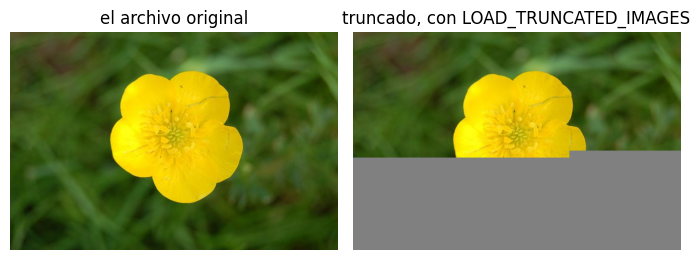

In [19]:
ImageFile.LOAD_TRUNCATED_IMAGES = True
rescatada = Image.open(f"{CORRUPTAS}/{archivos[12]}")
rescatada.load()
ImageFile.LOAD_TRUNCATED_IMAGES = False           # volver al valor por defecto

pixeles = np.asarray(rescatada).astype(float)
filas_planas = (pixeles.std(axis=(1, 2)) < 2).sum()
print("tamaño:", rescatada.size, f"  filas de un solo color: {filas_planas} de {pixeles.shape[0]}",
      "  color de la última fila:", pixeles[-1, 0].tolist())

fig, ejes = plt.subplots(1, 2, figsize=(7, 3.1))
ejes[0].imshow(Image.open(rutas_todas[elegidas[12]]))
ejes[0].set_title("el archivo original")
ejes[1].imshow(rescatada)
ejes[1].set_title("truncado, con LOAD_TRUNCATED_IMAGES")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

El error desaparece, pero la foto no se arregla: Pillow rellena lo que falta con gris (128, 128, 128). 211 de las 500 filas quedaron de un solo color, y el modelo entrenaría con media foto gris y la etiqueta de la flor completa. Además es un ajuste global: vale para todo el código que use Pillow en el proceso, no solo para este dataset. Por eso lo devolvimos a `False` enseguida.

## 8. Un `__getitem__` robusto

Con lo que medimos, armamos la defensa del video, con un cambio: además de `verify()`, decodificamos con `load()`, que es lo que atrapa los JPEG truncados. `abrir_imagen` hace cuatro cosas:

1. `verify()` revisa la estructura sin decodificar (atrapa, por ejemplo, un PNG truncado).
2. Reabre el archivo, porque después de `verify()` hay que reabrirlo, y decodifica con `load()`.
3. Rechaza las fotos cuyo lado más corto mide menos de 32 píxeles: ninguna transformación las arregla.
4. Deja la imagen en RGB, así que la gris, la con alfa y la CMYK quedan con tres canales. Para la gris y la CMYK basta `convert("RGB")`: la documentación dice que "This supports all possible conversions between “L”, “RGB” and “CMYK”" ([`Image.convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert)). Con transparencia hay que tener más cuidado, como muestra la celda siguiente.

Nuestra foto "con alfa" es opaca: la pasamos de RGB a RGBA, así que su canal alfa vale 255 en todas partes. Para ver qué hace `convert("RGB")` con transparencia de verdad, armamos un PNG con la flor recortada en un círculo: dentro, alfa 255; fuera, alfa 0, con el color (0, 0, 0) guardado debajo. Lo comparamos con la otra forma de pasar a RGB: pegar la imagen sobre un fondo blanco usando el canal alfa como máscara. Según la documentación de `paste`, "Where the mask is 255, the given image is copied as is. Where the mask is 0, the current value is preserved." ([`Image.paste`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.paste)):

modo: RGBA   esquina (transparente): (0, 0, 0, 0)   con convert: (0, 0, 0)   sobre blanco: (255, 255, 255)


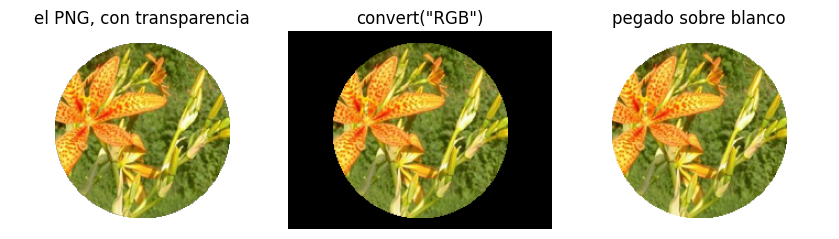

In [20]:
foto = Image.open(rutas_todas[FLOR]).convert("RGB").resize((240, 180))
fila, columna = np.mgrid[:180, :240]
dentro = (columna - 120) ** 2 + (fila - 90) ** 2 < 80 ** 2
rgba = np.zeros((180, 240, 4), dtype=np.uint8)          # fuera del círculo: color (0, 0, 0) y alfa 0
rgba[dentro, :3] = np.asarray(foto)[dentro]
rgba[dentro, 3] = 255
recorte = Image.fromarray(rgba)                         # cuatro canales: Pillow lo toma como RGBA

directo = recorte.convert("RGB")
compuesto = Image.new("RGB", recorte.size, (255, 255, 255))
compuesto.paste(recorte, mask=recorte.getchannel("A"))
print("modo:", recorte.mode, "  esquina (transparente):", recorte.getpixel((0, 0)),
      "  con convert:", directo.getpixel((0, 0)), "  sobre blanco:", compuesto.getpixel((0, 0)))

fig, ejes = plt.subplots(1, 3, figsize=(8.5, 2.4))
for eje, imagen, titulo in zip(ejes, [recorte, directo, compuesto],
                               ["el PNG, con transparencia", 'convert("RGB")', "pegado sobre blanco"]):
    eje.imshow(imagen)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

`convert("RGB")` descarta el canal alfa sin mirarlo: lo transparente queda con el color que estaba guardado debajo, aquí negro. El modelo vería un fondo negro que nadie dibujó, y si otro programa hubiera guardado otro color bajo la transparencia, vería ese otro. Pegar sobre un fondo con el alfa como máscara da lo que se ve en pantalla. Qué fondo usar (blanco, gris, el color medio de las fotos) es una decisión; lo importante es que sea el mismo para todas las imágenes, al entrenar y después.

`abrir_imagen` hace eso cuando la imagen tiene canal alfa, que se reconoce porque `getbands()` incluye `"A"` ([`Image.getbands`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.getbands)). Los `with` cierran el archivo al terminar cada bloque; `convert` y `paste` dejan una imagen nueva, ya cargada en memoria, que sigue sirviendo después de cerrar el archivo.

`FloresRobusto` llama a `abrir_imagen` y, si algo falla, anota el índice, el archivo y el error, y pasa a la foto siguiente de la lista. Además guarda qué índice entregó en cada pedido, que vamos a necesitar en la sección 9:

In [21]:
def abrir_imagen(ruta, lado_minimo=32):
    """Abre una foto y la deja en RGB, o lanza una excepción que dice qué está mal."""
    with Image.open(ruta) as imagen:
        imagen.verify()                      # revisa la estructura sin decodificar
    with Image.open(ruta) as imagen:         # verify la deja inutilizable: se reabre
        imagen.load()                        # decodifica ahora; un JPEG truncado falla aquí
        if min(imagen.size) < lado_minimo:
            raise ValueError(f"imagen demasiado pequeña: {imagen.width} x {imagen.height}")
        if "A" in imagen.getbands():         # con transparencia: pegar sobre blanco
            imagen = imagen.convert("RGBA")
            fondo = Image.new("RGB", imagen.size, (255, 255, 255))
            fondo.paste(imagen, mask=imagen.getchannel("A"))
            return fondo
        return imagen.convert("RGB")         # gris y CMYK pasan a tres canales


class FloresRobusto(Dataset):
    def __init__(self, rutas, etiquetas, transformacion=None):
        self.rutas = list(rutas)
        self.etiquetas = [int(e) for e in etiquetas]
        self.transformacion = transformacion
        self.errores = []                    # (índice, archivo, tipo de error, mensaje)
        self.entregadas = []                 # qué índice se entregó realmente en cada pedido

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        try:
            imagen = abrir_imagen(self.rutas[i])
        except Exception as error:
            self.errores.append((i, os.path.basename(self.rutas[i]), type(error).__name__, str(error)))
            return self[(i + 1) % len(self)]     # pasar a la siguiente
        self.entregadas.append(i)
        if self.transformacion:
            imagen = self.transformacion(imagen)
        return imagen, self.etiquetas[i]

    def resumen_errores(self):
        print(f"{len(self.errores)} errores")
        for i, archivo, tipo, mensaje in self.errores:
            print(f"  {i:4d}  {archivo:14s} {tipo:22s} {mensaje[:70]}")


rutas_c = [f"{CORRUPTAS}/{a}" for a in archivos]
robusto = FloresRobusto(rutas_c, etiquetas_c, transformacion_val)
cargador = DataLoader(robusto, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(0))
n = sum(len(y) for x, y in cargador)
print(f"época completa: {len(cargador)} lotes, {n} imágenes\n")
robusto.resumen_errores()

época completa: 13 lotes, 200 imágenes

5 errores
    58  flor_058.jpg   UnidentifiedImageError cannot identify image file '../data/flores_corruptas/flor_058.jpg'
    37  flor_037.jpg   UnidentifiedImageError cannot identify image file '../data/flores_corruptas/flor_037.jpg'
    12  flor_012.jpg   OSError                image file is truncated (4 bytes not processed)
   104  flor_104.jpg   ValueError             imagen demasiado pequeña: 24 x 18
   166  flor_166.jpg   FileNotFoundError      [Errno 2] No such file or directory: '../data/flores_corruptas/flor_16


La época se completa: 13 lotes, 200 imágenes. Los 5 errores registrados son los archivos que no tienen arreglo: el vacío, el de texto, el truncado, el diminuto y el faltante. La gris, la con alfa y la CMYK pasaron, convertidas a RGB (la con alfa, pegada sobre blanco; como es opaca, da lo mismo que con `convert`). Los errores aparecen en el orden en que el `DataLoader` pidió los archivos, que con `shuffle=True` es al azar.

## 9. Lo que esconde saltar a la siguiente

La época terminó, pero ¿qué vio el modelo? Pasar a la foto siguiente tiene tres efectos que no se notan si no se miden.

**Duplicados.** Cada pedido de un archivo malo se contestó con otro archivo:

In [22]:
veces = collections.Counter(robusto.entregadas)
print("pedidos:", len(robusto), "  imágenes distintas entregadas:", len(veces),
      "  entregadas dos veces:", [archivos[i] for i, v in veces.items() if v > 1])

vistas_por_clase = collections.Counter(etiquetas_c[i] for i in robusto.entregadas)
cambios = {c: vistas_por_clase[c] for c in range(100) if vistas_por_clase[c] != 2}
print("clases que no se vieron 2 veces (cada clase tiene 2 fotos):", cambios)

pedidos: 200   imágenes distintas entregadas: 195   entregadas dos veces: ['flor_059.jpg', 'flor_167.jpg', 'flor_038.jpg', 'flor_013.jpg', 'flor_105.jpg']
clases que no se vieron 2 veces (cada clase tiene 2 fotos): {15: 1, 16: 1, 42: 3, 47: 1, 52: 3, 53: 1, 74: 3, 77: 1, 86: 3, 94: 3}


200 pedidos y 195 fotos distintas: cada archivo malo fue reemplazado por el que le sigue en la lista, que así se vio dos veces. Como cada clase tiene dos fotos, el efecto se ve en las clases: las de los archivos malos se vieron una vez, y las de sus vecinos tres. Con 5 archivos malos entre 200 son detalles. El problema aparece cuando los errores no son aislados.

**Un problema sistemático, escondido.** Supongamos que la carpeta con las fotos de una clase no se copió al computador donde se entrena. Lo simulamos con las 522 fotos de las clases 0 a 9, que ordenamos por clase, como quedarían con una carpeta por clase. (En Oxford Flowers los archivos vienen en tramos de una misma clase, pero los tramos no siguen el orden de las clases: `00-acceso/01_un_dataset_propio`, sección 4.) Después cambiamos las rutas de la clase 3 (*sweet pea*, 56 fotos) a una carpeta que no existe. Recorremos una época con `FloresRobusto`:

In [23]:
clases = list(range(10))
rutas_10 = [r for r, e in zip(rutas_todas, etiquetas_todas) if e in clases]
etiquetas_10 = [int(e) for e in etiquetas_todas if e in clases]
orden = sorted(range(len(rutas_10)), key=lambda j: (etiquetas_10[j], rutas_10[j]))
rutas_10 = [rutas_10[j] for j in orden]
etiquetas_10 = [etiquetas_10[j] for j in orden]

PERDIDA = 3          # la carpeta de esta clase no se copió
rutas_rotas = [r.replace("/jpg/", "/sin_copiar/") if e == PERDIDA else r
               for r, e in zip(rutas_10, etiquetas_10)]

sistematico = FloresRobusto(rutas_rotas, etiquetas_10, transformacion_val)
etiquetas_vistas = []
for x, y in DataLoader(sistematico, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0)):
    etiquetas_vistas += y.tolist()

esperadas = collections.Counter(etiquetas_10)
vistas = collections.Counter(etiquetas_vistas)
print(f"{'clase':28s} {'en la lista':>11s} {'vistas':>7s}")
for c in clases:
    print(f"{c} {NOMBRES[c]:26s} {esperadas[c]:11d} {vistas[c]:7d}")
print("\nla época terminó sin excepciones;", len(sistematico.errores), "errores registrados")
mas_repetida, repeticiones = collections.Counter(sistematico.entregadas).most_common(1)[0]
print(f"la imagen más repetida: {os.path.basename(rutas_rotas[mas_repetida])} (clase {etiquetas_10[mas_repetida]}), "
      f"{repeticiones} veces en una época")

clase                        en la lista  vistas
0 pink primrose                       40      40
1 hard-leaved pocket orchid           60      60
2 canterbury bells                    40      40
3 sweet pea                           56       0
4 english marigold                    65     121
5 tiger lily                          45      45
6 moon orchid                         40      40
7 bird of paradise                    85      85
8 monkshood                           46      46
9 globe thistle                       45      45

la época terminó sin excepciones; 1596 errores registrados
la imagen más repetida: image_05147.jpg (clase 4), 57 veces en una época


La época terminó sin una sola excepción. Pero el modelo no vio ninguna foto de *sweet pea*, y la clase 4 (*english marigold*) se vio 121 veces en vez de 65. Cada pedido de la clase perdida saltó hacia adelante, archivo faltante tras archivo faltante, hasta la primera foto de la clase siguiente, que se entregó 57 veces en una época: la suya más las 56 de la clase perdida. Un modelo entrenado así nunca aprende qué es un *sweet pea*, y aprende de memoria una caléndula en particular.

Las 57 repeticiones salen de que las fotos perdidas están seguidas en la lista. Si estuvieran repartidas entre fotos de otras clases, cada una se reemplazaría por su vecina y quedarían duplicados sueltos, como con las 200 flores. La clase perdida desaparecería igual.

Ni siquiera el registro de errores dice cuántos archivos faltan: 1.596 errores para 56 archivos. El pedido del primer archivo faltante registra 56 errores antes de llegar a una foto buena, el del segundo 55, y así hasta 1: 56 + 55 + … + 1 = 56 · 57 / 2 = 1.596.

**Recursión.** Cada salto a la siguiente es una llamada nueva a `__getitem__` dentro de la anterior, y Python limita cuántas llamadas pueden estar anidadas. Si faltan miles de archivos seguidos, por ejemplo porque no se copió ninguna carpeta, el límite se alcanza:

In [24]:
print("límite de recursión de Python:", sys.getrecursionlimit())
carpeta_vacia = [f"{RAIZ}/no_existe/foto_{j:05d}.jpg" for j in range(5000)] + [rutas_todas[0]]
mucho_faltante = FloresRobusto(carpeta_vacia, [0] * len(carpeta_vacia), transformacion_val)
try:
    mucho_faltante[0]
except RecursionError as error:
    print("RecursionError:", error)
print("errores registrados antes de caer:", dict(collections.Counter(e[2] for e in mucho_faltante.errores)))

límite de recursión de Python: 1000
RecursionError: maximum recursion depth exceeded
errores registrados antes de caer: {'FileNotFoundError': 970, 'RecursionError': 1}


El límite es de 1.000 llamadas anidadas, y el `RecursionError` llegó después de registrar 971 errores: el resto de ese margen ya lo ocupaban las llamadas en curso del propio notebook. Además, uno de esos 971 no es un archivo malo: es el propio `RecursionError`, que saltó en la llamada más profunda, dentro de `abrir_imagen`. El `except Exception` lo atrapó y lo anotó como si fuera un problema del archivo; recién en el salto siguiente, que está fuera del `try`, el error se escapó hacia arriba. Es un error que no dice nada de archivos faltantes. La recursión se puede cambiar por un ciclo con un máximo de intentos (ejercicio 3), pero eso solo cambia el mensaje: el problema de fondo es intentar entrenar cuando faltan miles de archivos.

## 10. Revisar una vez, antes de entrenar

El `__getitem__` robusto mezcla dos preguntas: *¿qué archivos sirven?* y *¿qué le entrego al modelo?* La primera se puede contestar una sola vez, antes de entrenar, abriendo cada archivo con la misma `abrir_imagen`. Con la respuesta se decide:

- si alguna clase se quedó sin ninguna foto legible, se detiene todo;
- si la fracción de archivos con problemas supera un umbral, también;
- si no, el dataset se arma solo con los archivos buenos, y el informe de lo que se descartó queda impreso.

El umbral es una decisión de cada proyecto; aquí empezamos con 1%. Primero, el caso de la clase perdida:

In [25]:
def revisar(rutas, lado_minimo=32):
    """Abre cada archivo una vez. Devuelve los índices buenos y los problemas encontrados."""
    buenos, problemas = [], []
    for i, ruta in enumerate(rutas):
        try:
            abrir_imagen(ruta, lado_minimo)
            buenos.append(i)
        except Exception as error:
            problemas.append((i, os.path.basename(ruta), type(error).__name__))
    return buenos, problemas


def exigir_calidad(rutas, etiquetas, umbral=0.01):
    inicio = time.perf_counter()
    buenos, problemas = revisar(rutas)
    segundos = time.perf_counter() - inicio
    total = collections.Counter(etiquetas)
    legibles = collections.Counter(etiquetas[i] for i in buenos)
    clases_vacias = [c for c in total if legibles[c] == 0]
    fraccion = len(problemas) / len(rutas)
    print(f"revisados {len(rutas)} archivos en {segundos:.1f} s: {len(problemas)} con problemas ({fraccion:.1%})")
    for tipo, cuantos in collections.Counter(p[2] for p in problemas).most_common():
        print(f"   {cuantos:3d} {tipo}")
    if clases_vacias:
        raise RuntimeError(f"clases sin ninguna foto legible: {clases_vacias}")
    if fraccion > umbral:
        raise RuntimeError(f"{fraccion:.1%} de archivos con problemas supera el umbral de {umbral:.0%}")
    return buenos


try:
    exigir_calidad(rutas_rotas, etiquetas_10)
except RuntimeError as error:
    print("RuntimeError:", error)

revisados 522 archivos en 2.7 s: 56 con problemas (10.7%)
    56 FileNotFoundError
RuntimeError: clases sin ninguna foto legible: [3]


La clase perdida aparece antes de entrenar, con un mensaje que dice lo que pasa: 56 archivos no encontrados, el 10.7% del total, y la clase 3 sin ninguna foto. Ahora las 200 flores:

In [26]:
try:
    exigir_calidad(rutas_c, etiquetas_c)
except RuntimeError as error:
    print("RuntimeError:", error)

revisados 200 archivos en 1.5 s: 5 con problemas (2.5%)
     2 UnidentifiedImageError
     1 OSError
     1 ValueError
     1 FileNotFoundError
RuntimeError: 2.5% de archivos con problemas supera el umbral de 1%


El 2.5% de archivos con problemas supera el umbral de 1%, y la revisión se detiene. ¿Es mucho 2.5%? En un dataset que viene de una fuente confiable, sí: algo se rompió en el camino y vale la pena averiguar qué antes de entrenar. Si ya lo sabemos y lo aceptamos, se sube el umbral a propósito, y queda escrito en el código:

In [27]:
class FloresRevisadas(Flores):
    """Solo archivos que pasaron la revisión. Sin try: si algo falla ahora, que se note."""

    def __getitem__(self, i):
        imagen = abrir_imagen(self.rutas[i])
        if self.transformacion:
            imagen = self.transformacion(imagen)
        return imagen, self.etiquetas[i]


inicio = time.perf_counter()
buenos = exigir_calidad(rutas_c, etiquetas_c, umbral=0.05)
segundos = time.perf_counter() - inicio
revisadas = FloresRevisadas([rutas_c[i] for i in buenos], [etiquetas_c[i] for i in buenos], transformacion_val)
print(f"\nquedan {len(revisadas)} fotos")
print(f"a este ritmo, revisar las {len(rutas_todas)} flores tomaría unos {segundos / len(rutas_c) * len(rutas_todas):.0f} s")

revisados 200 archivos en 1.5 s: 5 con problemas (2.5%)
     2 UnidentifiedImageError
     1 OSError
     1 ValueError
     1 FileNotFoundError

quedan 195 fotos
a este ritmo, revisar las 8189 flores tomaría unos 61 s


Quedan 195 fotos. `FloresRevisadas` usa `abrir_imagen` sin `try`: si un archivo que pasó la revisión fallara durante el entrenamiento (porque alguien lo borró, por ejemplo), el error tiene que notarse, no esconderse.

Revisar cuesta lo mismo que decodificar cada foto una vez, del orden de una época sin entrenar. La última línea estima cuánto tomaría con las 8.189 flores: del orden de un minuto. Se paga una vez, antes de entrenar, y el resultado se puede guardar en un archivo para no repetirlo (ejercicio 4).

## 11. Monitorear la carga

Un pipeline sin errores todavía puede estar mal: entregar algunas fotos más veces que otras, saltarse otras, o ser lento. El video *Bugproof Pipelines* propone registrar qué imágenes se cargan, cuántas veces y cuánto tarda cada carga, y revisar esas cifras después de cada época. `Monitoreado` envuelve cualquier `Dataset` y anota eso, sin cambiar lo que entrega:

In [28]:
class Monitoreado(Dataset):
    """Envuelve otro Dataset: cuenta cuántas veces se pide cada índice y cuánto tarda."""

    def __init__(self, base):
        self.base = base
        self.accesos = collections.Counter()
        self.tiempos = collections.defaultdict(list)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        inicio = time.perf_counter()
        muestra = self.base[i]
        self.tiempos[i].append(time.perf_counter() - inicio)
        self.accesos[i] += 1
        return muestra

    def informe(self):
        n = len(self.base)
        sin_ver = n - len(self.accesos)
        repetidas = sum(1 for v in self.accesos.values() if v > 1)
        print(f"pedidos {sum(self.accesos.values())}   distintos {len(self.accesos)} de {n}   "
              f"sin ver {sin_ver} ({sin_ver / n:.1%})   repetidos {repetidas}")


monitor = Monitoreado(revisadas)
cargador = DataLoader(monitor, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(0))
print("muestreador que arma shuffle=True:", type(cargador.sampler).__name__,
      "  con reemplazo:", cargador.sampler.replacement)
for x, y in cargador:
    pass
monitor.informe()

muestreador que arma shuffle=True: RandomSampler   con reemplazo: False


pedidos 195   distintos 195 de 195   sin ver 0 (0.0%)   repetidos 0


Cada foto se pidió exactamente una vez, que es lo que tiene que pasar en una época. `shuffle=True` arma por dentro un `RandomSampler` sin reemplazo ("A sequential or shuffled sampler will be automatically constructed based on the shuffle argument to a DataLoader", [*Data Loading Order and Sampler*](https://docs.pytorch.org/docs/2.11/data.html#data-loading-order-and-sampler)), y sin reemplazo significa, según su documentación, "sample from a shuffled dataset" ([`RandomSampler`](https://docs.pytorch.org/docs/2.11/data.html#torch.utils.data.RandomSampler)): recorrer el dataset entero en otro orden.

**Un bug de muestreo.** El mismo `RandomSampler` con `replacement=True`: cada pedido sortea una foto al azar entre todas, sin acordarse de las anteriores. Puede llegar al código al copiar un muestreador pensado para otra cosa, como sobremuestrear las clases chicas. No da ningún error:

In [29]:
monitor_con_reemplazo = Monitoreado(revisadas)
muestreador = RandomSampler(monitor_con_reemplazo, replacement=True, generator=torch.Generator().manual_seed(0))
for x, y in DataLoader(monitor_con_reemplazo, batch_size=16, sampler=muestreador):
    pass
monitor_con_reemplazo.informe()
n = len(revisadas)
print(f"\nesperado sin ver: (1 - 1/n)^n = {(1 - 1 / n) ** n:.1%}   y 1/e = {math.exp(-1):.1%}")

pedidos 195   distintos 122 de 195   sin ver 73 (37.4%)   repetidos 53

esperado sin ver: (1 - 1/n)^n = 36.7%   y 1/e = 36.8%


73 de las 195 fotos (37.4%) no se vieron en toda la época, y 53 se vieron más de una vez. ¿Por qué tantas? En cada uno de los $n$ sorteos, una foto dada sale con probabilidad $1/n$ y no sale con probabilidad $1 - 1/n$. Que no salga en ninguno de los $n$ sorteos tiene probabilidad

$$\left(1 - \frac{1}{n}\right)^n \longrightarrow \frac{1}{e} \approx 0.368 \quad \text{cuando } n \text{ crece.}$$

Con $n = 195$ da 36.7%, y medimos 37.4%. Más de un tercio de los datos se pierde en cada época, sin aviso.

¿Es mucha la diferencia entre 37.4% y 36.7%? Depende de cuánto cambia la medición de una semilla a otra. Para averiguarlo no hace falta cargar fotos: el muestreador solo entrega índices. Repetimos el sorteo con 200 semillas, para tres tamaños de dataset:

In [30]:
for n in [195, 1000, len(rutas_todas)]:
    fracciones = []
    for semilla in range(200):
        sorteo = list(RandomSampler(range(n), replacement=True, generator=torch.Generator().manual_seed(semilla)))
        fracciones.append(1 - len(set(sorteo)) / n)
    fracciones = torch.tensor(fracciones)
    print(f"n = {n:5d}:  sin ver, en promedio {fracciones.mean():.2%}   dispersión entre semillas {fracciones.std():.2%}"
          f"   fórmula {(1 - 1 / n) ** n:.2%}")

n =   195:  sin ver, en promedio 36.74%   dispersión entre semillas 2.20%   fórmula 36.69%


n =  1000:  sin ver, en promedio 36.74%   dispersión entre semillas 1.00%   fórmula 36.77%


n =  8189:  sin ver, en promedio 36.78%   dispersión entre semillas 0.36%   fórmula 36.79%


En promedio, la fracción sin ver coincide con la fórmula en los tres tamaños, a menos de una décima de punto. Lo que cambia con $n$ es la dispersión: 2.2 puntos con 195 fotos, 1.0 con 1.000 y 0.36 con 8.189. Baja más o menos como $1/\sqrt{n}$: con 42 veces más fotos, unas 6 veces menos. Nuestro 37.4% queda a 0.7 puntos de la fórmula, menos de una dispersión: es lo esperable con 195 fotos.

Con las 8.189 flores contamos también cuántas veces sale cada una, con la semilla 0. Para una foto dada, esa cuenta es una binomial: $n$ sorteos, cada uno con probabilidad $1/n$ de elegirla. Con $n$ grande, la binomial es casi igual a una distribución de Poisson de media 1, que da probabilidad $e^{-1}/k!$ a salir $k$ veces:

In [31]:
n = len(rutas_todas)
indices = list(RandomSampler(range(n), replacement=True, generator=torch.Generator().manual_seed(0)))
conteo = torch.bincount(torch.tensor(indices), minlength=n)
veces_vista = torch.bincount(conteo)
print(f"{'veces vista':>11s} {'fotos':>6s} {'fracción':>9s} {'Poisson(1)':>11s}")
for k, cuantas in enumerate(veces_vista.tolist()):
    print(f"{k:11d} {cuantas:6d} {cuantas / n:9.2%} {math.exp(-1) / math.factorial(k):11.2%}")

veces vista  fotos  fracción  Poisson(1)
          0   3102    37.88%      36.79%
          1   2938    35.88%      36.79%
          2   1429    17.45%      18.39%
          3    532     6.50%       6.13%
          4    151     1.84%       1.53%
          5     29     0.35%       0.31%
          6      8     0.10%       0.05%


Con esta semilla, el 37.9% de las flores no se vería nunca en la época, mientras 37 se verían 5 o 6 veces. Cada fila calza con Poisson(1), con diferencias de 1.1 puntos porcentuales o menos. La que más se aleja es la del 0: 1.1 puntos sobre el 36.8%, unas tres veces la dispersión entre semillas que medimos para $n = 8.189$. La semilla 0 cayó cerca de un extremo; otra semilla daría números algo distintos, con la misma forma. Este bug no produce errores ni cambia la forma de los lotes; solo lo muestra el monitoreo.

**Los tiempos.** Lo último que anota el monitor es cuánto tarda cada carga. Un tiempo aislado puede ser ruido del computador (otro programa usando la CPU justo en ese momento), así que recorremos dos épocas más y tomamos, para cada foto, la mediana de sus tres tiempos:

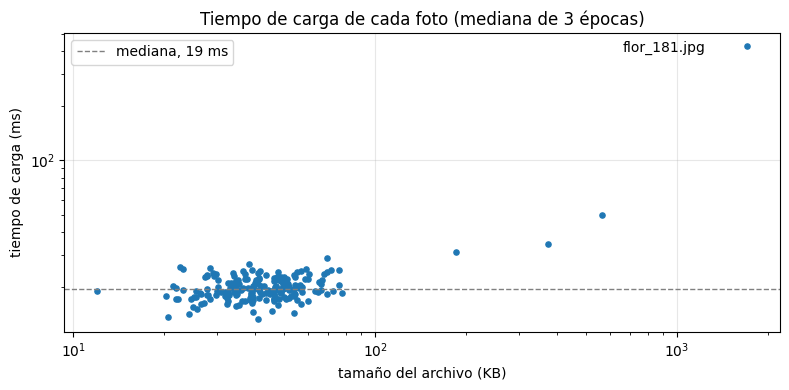

archivo            tamaño      píxeles    tiempo
flor_181.jpg    1712.5 KB  5336 x 4000   424.5 ms   (22 veces la mediana)
flor_127.png     566.4 KB   666 x 500     50.0 ms   (3 veces la mediana)
flor_195.jpg     375.2 KB   642 x 500     34.3 ms   (2 veces la mediana)
flor_143.jpg     185.7 KB   751 x 500     31.0 ms   (2 veces la mediana)


In [32]:
for epoca in range(2):
    for x, y in DataLoader(monitor, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(epoca + 1)):
        pass

nombres_r = [os.path.basename(r) for r in revisadas.rutas]
kb = [os.path.getsize(r) / 1000 for r in revisadas.rutas]
ms = [float(np.median(monitor.tiempos[i])) * 1000 for i in range(len(revisadas))]
mediana = float(np.median(ms))

fig, eje = plt.subplots(figsize=(8, 4))
eje.scatter(kb, ms, s=14)
lenta = max(range(len(ms)), key=lambda i: ms[i])
eje.annotate(nombres_r[lenta], (kb[lenta], ms[lenta]), textcoords="offset points", xytext=(-90, -4))
eje.axhline(mediana, color="gray", linestyle="--", linewidth=1, label=f"mediana, {mediana:.0f} ms")
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_xlabel("tamaño del archivo (KB)")
eje.set_ylabel("tiempo de carga (ms)")
eje.set_title("Tiempo de carga de cada foto (mediana de 3 épocas)")
eje.grid(alpha=0.3)
eje.legend()
plt.tight_layout()
plt.show()

print(f"{'archivo':14s} {'tamaño':>10s} {'píxeles':>12s} {'tiempo':>9s}")
for i in sorted(range(len(ms)), key=lambda i: -ms[i])[:4]:
    ancho, alto = Image.open(revisadas.rutas[i]).size
    print(f"{nombres_r[i]:14s} {kb[i]:7.1f} KB {ancho:5d} x {alto:<5d} {ms[i]:6.1f} ms   ({ms[i] / mediana:.0f} veces la mediana)")

La gigante, `flor_181.jpg`, se separa del resto: tarda más de diez veces la mediana, porque decodificar y achicar 5.336 × 4.000 píxeles cuesta mucho más que una foto de 500 × 667. Las siguientes de la tabla quedan mucho más cerca de la mediana. Los tiempos exactos cambian de un computador a otro y entre ejecuciones; lo que se mantiene es que la gigante queda sola, muy por encima de la nube. Una foto gigante no rompe nada, solo frena; si hubiera muchas, cada época se alargaría sin explicación. Arreglarla es fácil una vez que se sabe que existe: achicarla una vez y guardar la versión chica.

## 12. Con varios procesos

Hasta aquí todo corrió con `num_workers=0`, en el proceso principal. Con `num_workers > 0`, el `DataLoader` lanza procesos aparte que preparan los lotes en paralelo (`00-datos/01_transforms_dataset_y_dataloader` del módulo 2, ejercicio 6). La documentación explica qué recibe cada proceso: "the dataset, collate_fn, and worker_init_fn are passed to each worker, where they are used to initialize, and fetch data", y en Windows y macOS los recibe "through pickle serialization" ([*Multi-process data loading*](https://docs.pytorch.org/docs/2.11/data.html#multi-process-data-loading) y [*Platform-specific behaviors*](https://docs.pytorch.org/docs/2.11/data.html#platform-specific-behaviors)). O sea, cada proceso trabaja con **su propia copia** del dataset. La lista `self.errores` de `FloresRobusto` se llena en la copia, y el proceso principal nunca la ve.

No lanzamos procesos aparte desde el notebook: en Windows suelen fallar con clases definidas en un notebook, porque, según la misma página, las funciones se pasan "as references only, not bytecode" y el proceso nuevo no encuentra el código. Pero podemos simular lo que pasa: serializar el dataset con `pickle`, que es lo que hacen Windows y macOS, y recorrer la copia:

In [33]:
original = FloresRobusto(rutas_c, etiquetas_c, transformacion_val)
copia = pickle.loads(pickle.dumps(original))          # lo que recibe cada proceso en Windows y macOS
for x, y in DataLoader(copia, batch_size=16):
    pass
print("errores en la copia   :", len(copia.errores))
print("errores en el original:", len(original.errores))

errores en la copia   : 5
errores en el original: 0


La copia registró los 5 errores; el original, ninguno. Con procesos de verdad pasa lo mismo, y además cada proceso tendría su propia lista con una parte de los errores.

La salida es mandar la información por el camino que sí vuelve al proceso principal: el lote. `FloresConAviso` devuelve `None` en lugar de la imagen cuando una foto falla, junto con el índice y el tipo de error. Una `collate_fn` propia separa las muestras buenas de los avisos antes de apilar, y entrega los avisos junto al lote:

In [34]:
class FloresConAviso(Dataset):
    """Si una foto falla, devuelve None y deja que el lote lo cuente."""

    def __init__(self, rutas, etiquetas, transformacion):
        self.rutas = list(rutas)
        self.etiquetas = [int(e) for e in etiquetas]
        self.transformacion = transformacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        try:
            imagen = abrir_imagen(self.rutas[i])
        except Exception as error:
            return None, (i, type(error).__name__)
        return self.transformacion(imagen), self.etiquetas[i]


def juntar_sin_fallas(muestras):
    buenas = [m for m in muestras if m[0] is not None]
    fallas = [m[1] for m in muestras if m[0] is None]
    if not buenas:                           # falló el lote entero: no hay nada que apilar
        return None, None, fallas
    x, y = default_collate(buenas)
    return x, y, fallas


cargador = DataLoader(FloresConAviso(rutas_c, etiquetas_c, transformacion_val), batch_size=16,
                      collate_fn=juntar_sin_fallas)
todas_las_fallas, tamanos = [], []
for x, y, fallas in cargador:
    todas_las_fallas += fallas
    if x is not None:
        tamanos.append(len(y))
print("tamaños de los lotes:", tamanos)
print("fallas recibidas en el proceso principal:", todas_las_fallas)

tamaños de los lotes: [15, 16, 15, 15, 16, 16, 15, 16, 16, 16, 15, 16, 8]
fallas recibidas en el proceso principal: [(12, 'OSError'), (37, 'UnidentifiedImageError'), (58, 'UnidentifiedImageError'), (104, 'ValueError'), (166, 'FileNotFoundError')]


Las fallas llegan al proceso principal con cada lote, y ahí se pueden contar, guardar o usar para detener el entrenamiento si pasan de un umbral. No hay duplicados ni recursión: la foto mala simplemente no entra al lote. El costo es que los lotes con fallas salen más chicos (15 en vez de 16; el último trae las 8 que sobran de 200). Y hay un caso que cuidar: si fallan todas las muestras de un lote, no queda nada que apilar, y `default_collate` con una lista vacía da error. Por eso `juntar_sin_fallas` devuelve `None` en ese caso, y el ciclo de entrenamiento tiene que saltarse ese lote. Con unas pocas fallas da igual. Si fueran muchas, es la señal de que había que revisar antes de entrenar (sección 10).

## 13. Resumen

- El **aumento de datos** aplica transformaciones aleatorias cada vez que se pide una foto, así que cada época ve versiones distintas. Va solo en el entrenamiento: la validación tiene que dar el mismo tensor cada vez. El azar viene del generador de PyTorch, y `torch.manual_seed` lo hace reproducible.
- Antes de entrenar, **mira** varias versiones aumentadas de la misma foto, desnormalizadas. Todas iguales: el aumento no se aplica. Irreconocibles: es demasiado agresivo. Colores saturados o negros: la normalización está mal. La media y la desviación de un lote detectan lo último sin mirar.
- `RandomResizedCrop` usa por defecto `scale=(0.08, 1.0)`: recortes que pueden quedarse con menos de un cuarto de la foto una de cada cuatro veces. El rango se elige mirando los datos.
- Los archivos rotos fallan en lugares distintos: **al abrir** (vacíos, texto, faltantes), **al decodificar** (truncados) o **al transformar** (1 o 4 canales). Algunos no fallan y deberían: una miniatura agrandada 14 veces llega al modelo como una mancha.
- `Image.verify()` no decodifica: atrapa un PNG truncado pero no un JPEG truncado. Solo `load()` asegura que una foto se puede usar. `LOAD_TRUNCATED_IMAGES = True` no arregla nada: rellena lo que falta con gris, y vale para todo el proceso.
- `convert("RGB")` arregla las fotos grises y CMYK, pero con transparencia descarta el alfa y deja a la vista el color guardado debajo. Para esas, se pega la imagen sobre un fondo, con el alfa como máscara.
- Un `__getitem__` robusto (`verify`, `load`, tamaño mínimo, pasar a RGB, registrar y pasar a la siguiente) completa la época, pero **esconde** problemas: duplica fotos, cambia la proporción de las clases, puede hacer desaparecer una clase entera sin una excepción, y con muchos archivos seguidos faltantes termina en `RecursionError`.
- Mejor **revisar una vez antes de entrenar**: detener todo si una clase queda vacía o si los archivos malos superan un umbral, y entrenar solo con los buenos, sin `try` en `__getitem__`.
- El **monitoreo** cuenta accesos y tiempos. Detecta un muestreo con reemplazo, que deja sin ver alrededor de $1/e \approx 37\%$ de los datos en cada época, y las fotos lentas. Para comparar una medición con una fórmula hay que saber cuánto cambia la medición de una semilla a otra.
- Con `num_workers > 0` cada proceso tiene su propia copia del dataset: lo que el dataset anota en `self` no vuelve al proceso principal. La información tiene que viajar en el lote, por ejemplo con una `collate_fn` propia.

## Ejercicios

1. Cambia `scale` del aumento razonable a `(0.08, 1.0)`, el valor por defecto, y mira las ocho versiones de la sección 4. ¿En cuántas se sigue viendo la flor? Repite con dos fotos más en que la flor ocupe poco de la imagen.
2. Agrega `transforms.RandomVerticalFlip()` al aumento razonable. ¿Tiene sentido para fotos de flores? ¿Y para los dígitos de MNIST del módulo 2? Piensa en qué versiones aumentadas podrían aparecer de verdad en una foto nueva.
3. Escribe una versión de `FloresRobusto.__getitem__` con un ciclo en vez de recursión, que pruebe como máximo 10 archivos seguidos y lance un `RuntimeError` con un mensaje claro si ninguno sirve. Pruébala con la carpeta inexistente de la sección 9.
4. Haz que `revisar` guarde su resultado en un archivo JSON con el tamaño y la fecha de modificación de cada archivo (`os.path.getsize`, `os.path.getmtime`), y que en la ejecución siguiente solo vuelva a abrir los archivos nuevos o modificados. ¿Cuánto tarda la segunda revisión?
5. Predice y comprueba: con un `RandomSampler` con reemplazo y `num_samples=2 * n`, ¿qué fracción de las fotos queda sin ver en una época? Generaliza la fórmula de la sección 11.
6. Usa `Monitoreado` para medir el tiempo de carga de 500 flores de Oxford y grafica el tiempo contra el número de píxeles (ancho × alto) en vez del tamaño del archivo. ¿Cuál de los dos explica mejor el tiempo?
7. En un script `.py`, recorre `FloresRobusto` con `num_workers=2` sobre las 200 flores corruptas e imprime `len(dataset.errores)` al terminar. Haz lo mismo con `FloresConAviso` y `juntar_sin_fallas`, contando las fallas recibidas. ¿Coincide con lo que simulamos con `pickle`? (En Windows, el código que crea el `DataLoader` tiene que ir dentro de `if __name__ == "__main__":`, y las clases y funciones, fuera de ese bloque.)

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026. Los links de PyTorch y `torchvision` apuntan a las versiones instaladas (PyTorch 2.11 y `torchvision` 0.26). Los de Pillow apuntan a la versión estable de la documentación; los textos citados son idénticos a los de la versión instalada, Pillow 12.3.

**Del material del curso**

- El video *Bugproof Pipelines* del curso propone el aumento de datos al vuelo, mirar unas ocho versiones aumentadas de la misma foto desnormalizándolas, los cuatro diagnósticos de la tabla de la sección 4, las defensas de `__getitem__` (`verify()`, tamaño mínimo, `convert('RGB')`, registrar el error y pasar a la siguiente imagen) y el monitoreo de accesos y tiempos. Las mediciones de lo que detecta cada defensa y de lo que esconde son nuestras.

**Documentación de Pillow**

- [`PIL.Image.open`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.open): "This is a lazy operation; this function identifies the file, but the file remains open and the actual image data is not read from the file until you try to process the data (or call the load() method)." Excepciones: "FileNotFoundError – If the file cannot be found." y "PIL.UnidentifiedImageError – If the image cannot be opened and identified."
- [`Image.verify`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.verify): "Verifies the contents of a file. For data read from a file, this method attempts to determine if the file is broken, without actually decoding the image data. If this method finds any problems, it raises suitable exceptions. If you need to load the image after using this method, you must reopen the image file."
- [`Image.load`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.load): "Allocates storage for the image and loads the pixel data. In normal cases, you don’t need to call this method, since the Image class automatically loads an opened image when it is accessed for the first time."
- [`Image.convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert): "Returns a converted copy of this image." y "This supports all possible conversions between “L”, “RGB” and “CMYK”."
- [`Image.paste`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.paste): "If a mask is given, this method updates only the regions indicated by the mask. You can use either “1”, “L”, “LA”, “RGBA” or “RGBa” images (if present, the alpha band is used as mask). Where the mask is 255, the given image is copied as is. Where the mask is 0, the current value is preserved."
- [`Image.getbands`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.getbands): "Returns a tuple containing the name of each band in this image. For example, getbands on an RGB image returns (“R”, “G”, “B”)."
- [`Image.getchannel`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.getchannel): "Returns an image containing a single channel of the source image."
- [`ImageFile.LOAD_TRUNCATED_IMAGES`](https://pillow.readthedocs.io/en/stable/reference/ImageFile.html#PIL.ImageFile.LOAD_TRUNCATED_IMAGES): "Whether or not to load truncated image files. User code may change this." (valor por defecto `False`).

**Documentación de `torchvision` 0.26**

- [*Transforming images, videos, boxes and more*](https://docs.pytorch.org/vision/0.26/transforms.html#transform-classes-functionals-and-kernels), nota de la sección *Transform classes, functionals, and kernels*: "Random transforms like RandomCrop will randomly sample some parameter each time they’re called." y "The get_params() class method of the transforms class can be used to perform parameter sampling when using the functional APIs."
- [`RandomResizedCrop`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomResizedCrop.html): firma `RandomResizedCrop(size, scale=(0.08, 1.0), ratio=(0.75, 1.3333333333333333), ...)`; "A crop of the original image is made: the crop has a random area (H * W) and a random aspect ratio. This crop is finally resized to the given size. This is popularly used to train the Inception networks." y, del parámetro `scale`: "Specifies the lower and upper bounds for the random area of the crop, before resizing. The scale is defined with respect to the area of the original image."
- [`RandomHorizontalFlip`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomHorizontalFlip.html): "Horizontally flip the given image randomly with a given probability." y "probability of the image being flipped. Default value is 0.5".
- [`RandomRotation`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomRotation.html): "If degrees is a number instead of sequence like (min, max), the range of degrees will be (-degrees, +degrees)." y, del parámetro `fill`: "Pixel fill value for the area outside the rotated image. Default is 0."
- [`ColorJitter`](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.ColorJitter.html): "brightness_factor is chosen uniformly from [max(0, 1 - brightness), 1 + brightness]", y lo mismo para `contrast` y `saturation`.

**Documentación de PyTorch 2.11** ([`torch.utils.data`](https://docs.pytorch.org/docs/2.11/data.html))

- *Data Loading Order and Sampler*: "A sequential or shuffled sampler will be automatically constructed based on the shuffle argument to a DataLoader."
- [`RandomSampler`](https://docs.pytorch.org/docs/2.11/data.html#torch.utils.data.RandomSampler): "Samples elements randomly. If without replacement, then sample from a shuffled dataset. If with replacement, then user can specify num_samples to draw."
- *Multi-process data loading*: "In this mode, each time an iterator of a DataLoader is created (e.g., when you call enumerate(dataloader)), num_workers worker processes are created. At this point, the dataset, collate_fn, and worker_init_fn are passed to each worker, where they are used to initialize, and fetch data."
- *Platform-specific behaviors*: "On Windows and MacOS, spawn() is the default multiprocessing start method. Using spawn(), another interpreter is launched which runs your main script, followed by the internal worker function that receives the dataset, collate_fn and other arguments through pickle serialization." y "(this is needed since functions are pickled as references only, not bytecode.)"
- *Randomness in multi-process data loading*: "By default, each worker will have its PyTorch seed set to base_seed + worker_id".

**Lo que no viene de una fuente** son los números de este notebook (diferencias entre versiones, áreas de los recortes, estadísticas por canal, errores, conteos, probabilidades y tiempos): todos salen de las celdas de código. También son nuestros la carpeta de flores dañadas, la tabla de la etapa en que falla cada archivo, la comparación de `verify()` con JPEG y PNG, la clase perdida y su conteo de errores, la cuenta de $1/e$, la dispersión entre semillas y la aproximación de la binomial por Poisson(1) (probabilidad estándar), el PNG con transparencia y la elección del fondo blanco, y la simulación de los procesos con `pickle`.